# Spatial Encoding Comparison

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 07.04.2026
- Date of Last Modification: 11.04.2026 (by Sebastian Birk (sb75@sanger.ac.uk))

=== Data points per (ablation, region_key) ===
region_key                        Sub_molecular_tissue_region  ccf_region_name
ablation                                                                      
stjepa_v2_coord_aligned                                     9                9
stjepa_v2_coord_aligned_09995ema                            9                9
stjepa_v2_segment                                           9                9

Saved to /nfs/team361/sb75/stjepa-reproducibility/artifacts/ablation/results/niche_identification_spatial_encoding_ablations.csv

Saved ablation_spatial_encoding_niche_NMI_comparison.svg / .pdf / .png
Saved ablation_spatial_encoding_niche_ARI_comparison.svg / .pdf / .png


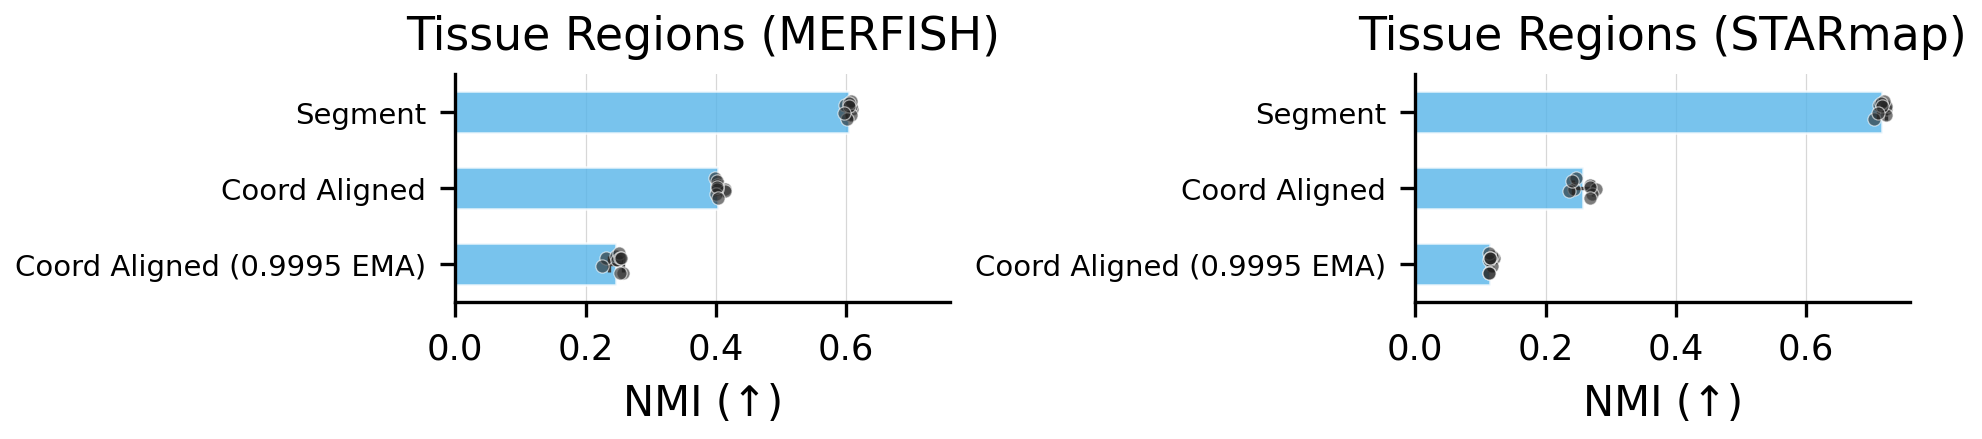

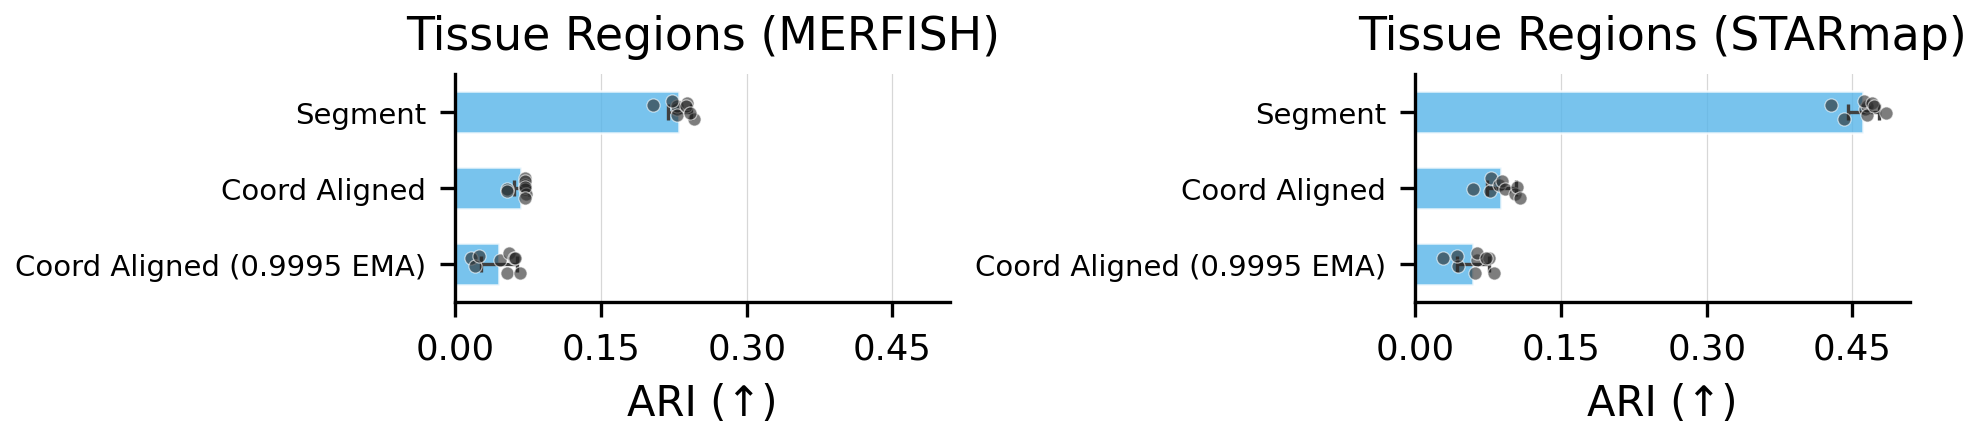


Saved batch integration dataframe to /nfs/team361/sb75/stjepa-reproducibility/artifacts/ablation/results/batch_integration_spatial_encoding_ablations.csv

=== Batch integration metrics ===
                        ablation      ASW      MMD        iLISI
         stjepa_v2_coord_aligned 0.067639 0.080767 2.384186e-07
stjepa_v2_coord_aligned_09995ema 0.110224 0.111342 2.384186e-07
               stjepa_v2_segment 0.018464 0.021318 1.070867e-01
Saved ablation_spatial_encoding_batch_integration_iLISI.svg / .pdf / .png
Saved ablation_spatial_encoding_batch_integration_ASW.svg / .pdf / .png
Saved ablation_spatial_encoding_batch_integration_MMD.svg / .pdf / .png


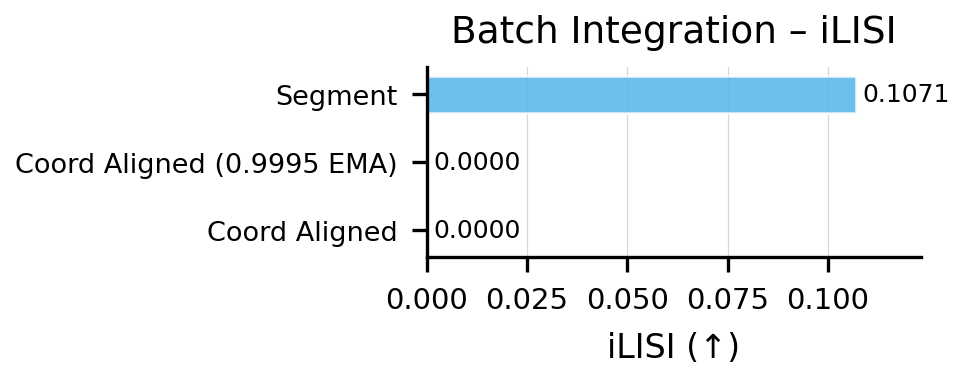

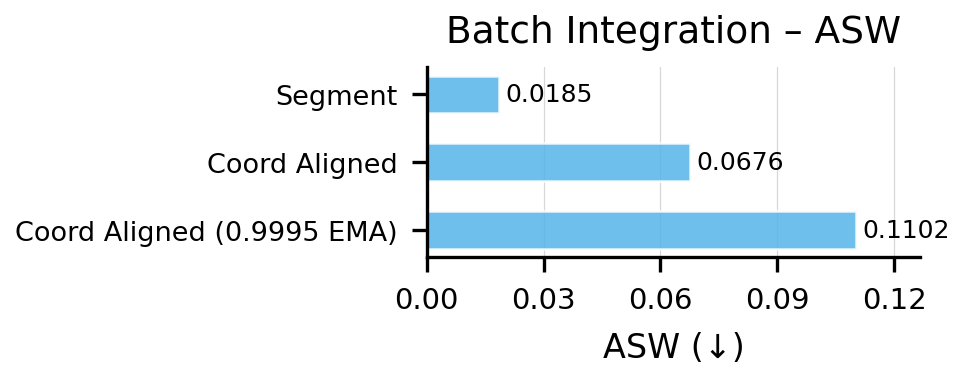

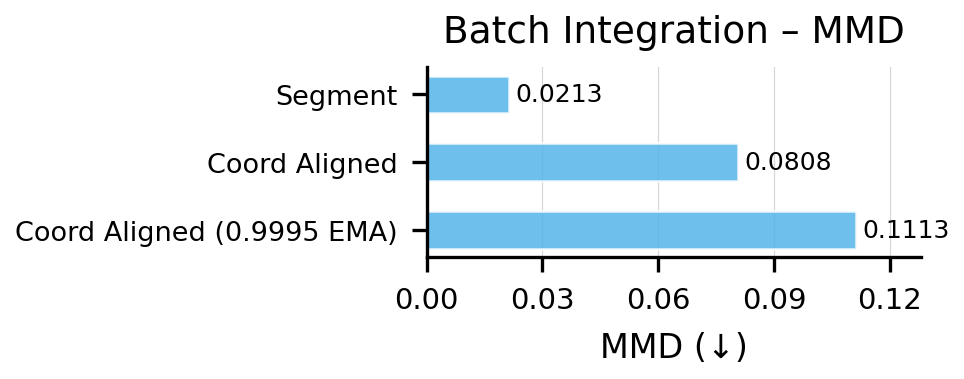

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
from pathlib import Path

# ---------------------------------------------------------------------------
# 1. Configuration
# ---------------------------------------------------------------------------
ablation_timestamp_pairs = [
    ("stjepa_v2_segment",                "21032026_085513_196"),
    ("stjepa_v2_coord_aligned",          "10042026_193042_980"),
    ("stjepa_v2_coord_aligned_09995ema", "11042026_014620_031"),
]

ABLATION_LABELS = {
    "stjepa_v2_segment":                "Segment",
    "stjepa_v2_coord_aligned":          "Coord Aligned",
    "stjepa_v2_coord_aligned_09995ema": "Coord Aligned (0.9995 EMA)",
}

COLOR_MAP = {a: "#56B4E9" for a, _ in ablation_timestamp_pairs}

base_path = Path("/nfs/team361/sb75/stjepa-reproducibility/artifacts/ablation")
results_dir = base_path / "results"
figures_dir = base_path / "figures"
results_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# Panel titles and ordering
REGION_TITLES = {
    "ccf_region_name":             "Tissue Regions (MERFISH)",
    "Sub_molecular_tissue_region": "Tissue Regions (STARmap)",
}
REGION_ORDER = ["ccf_region_name", "Sub_molecular_tissue_region"]

# ---------------------------------------------------------------------------
# 2. Load niche identification CSVs
# ---------------------------------------------------------------------------
frames = []
for ablation, timestamp in ablation_timestamp_pairs:
    fpath = (
        base_path / ablation / timestamp
        / "mmb0-1b_smb1-1b_1p_neighborhood_emb_niche_identification_metrics_res_sweep.csv"
    )
    if not fpath.exists():
        print(f"[WARN] File not found, skipping: {fpath}")
        continue
    df = pd.read_csv(fpath)
    df["ablation"] = ablation
    df["model_timestamp"] = timestamp
    frames.append(df)

if not frames:
    raise FileNotFoundError("No niche identification CSV files were found.")

df_all = pd.concat(frames, ignore_index=True)

print("=== Data points per (ablation, region_key) ===")
print(df_all.groupby(["ablation", "region_key"]).size().unstack(fill_value=0))
print()

df_all.to_csv(results_dir / "niche_identification_spatial_encoding_ablations.csv", index=False)
print(f"Saved to {results_dir / 'niche_identification_spatial_encoding_ablations.csv'}\n")

# ---------------------------------------------------------------------------
# 3. Style settings
# ---------------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 9,
    "axes.labelsize": 10,
    "axes.titlesize": 11,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "legend.fontsize": 8.5,
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.05,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
})

# ---------------------------------------------------------------------------
# 4. Niche identification plot
# ---------------------------------------------------------------------------
def plot_niche_horizontal(
    df: pd.DataFrame,
    metric: str,
    ablation_order: list[str],
    higher_is_better: bool = True,
):
    region_keys = REGION_ORDER
    n_panels = len(region_keys)
    n_ab = len(ablation_order)
    row_height = 0.25

    fig, axes = plt.subplots(
        1, n_panels,
        figsize=(3.2 * n_panels, row_height * n_ab + 0.7),
        sharex=True,
        constrained_layout=True,
    )
    if n_panels == 1:
        axes = [axes]

    for ax, rk in zip(axes, region_keys):
        sub = df[df["region_key"] == rk]

        mean_map = {}
        for a in ablation_order:
            vals = sub.loc[sub["ablation"] == a, metric].values
            mean_map[a] = np.mean(vals) if len(vals) > 0 else 0

        sorted_ablations = sorted(
            ablation_order,
            key=lambda a: mean_map[a],
            reverse=not higher_is_better,
        )

        means, sds, all_vals = [], [], []
        for a in sorted_ablations:
            vals = sub.loc[sub["ablation"] == a, metric].values
            means.append(np.mean(vals) if len(vals) > 0 else 0)
            sds.append(np.std(vals) if len(vals) > 0 else 0)
            all_vals.append(vals)

        y = np.arange(n_ab)
        bar_colors = [COLOR_MAP[a] for a in sorted_ablations]

        ax.barh(
            y, means, height=0.55,
            color=bar_colors, edgecolor="white", linewidth=0.6,
            alpha=0.80, zorder=2,
        )

        ax.errorbar(
            means, y, xerr=sds,
            fmt="none", ecolor="0.25", elinewidth=0.8,
            capsize=2.0, capthick=0.8, zorder=3,
        )

        rng = np.random.default_rng(42)
        for i, vals in enumerate(all_vals):
            n_pts = len(vals)
            if n_pts == 0:
                continue
            jitter = rng.uniform(-0.15, 0.15, size=n_pts)
            ax.scatter(
                vals, np.full(n_pts, i) + jitter,
                s=10, color="0.15", edgecolor="white",
                linewidth=0.3, zorder=4, alpha=0.60,
            )

        pretty_rk = REGION_TITLES.get(rk, rk.replace("_", " "))
        ax.set_title(pretty_rk, fontweight="medium")
        ax.set_yticks(y)
        ax.set_yticklabels(
            [ABLATION_LABELS.get(a, a) for a in sorted_ablations],
            fontsize=7,
        )
        ax.set_xlabel(f"{metric} (\u2191)")
        ax.set_ylim(-0.5, n_ab - 0.5)
        ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(5))
        ax.grid(axis="x", linewidth=0.3, alpha=0.5)

    return fig


# ---------------------------------------------------------------------------
# 5. Generate and save niche identification figures
# ---------------------------------------------------------------------------
ablation_order = [a for a, _ in ablation_timestamp_pairs]

for metric in ["NMI", "ARI"]:
    fig = plot_niche_horizontal(df_all, metric=metric, ablation_order=ablation_order, higher_is_better=True)
    for ext in ["svg", "pdf", "png"]:
        out = figures_dir / f"ablation_spatial_encoding_niche_{metric}_comparison.{ext}"
        fig.savefig(out)
    print(f"Saved ablation_spatial_encoding_niche_{metric}_comparison.svg / .pdf / .png")

plt.show()

# ===========================================================================
# 6. Batch integration metrics
# ===========================================================================
batch_frames = []
for ablation, timestamp in ablation_timestamp_pairs:
    fpath = (
        base_path / ablation / timestamp
        / "mmb0-1b_smb1-1b_1p_neighborhood_emb_batch_integration_metrics.csv"
    )
    if not fpath.exists():
        print(f"[WARN] Batch file not found, skipping: {fpath}")
        continue
    df_batch = pd.read_csv(fpath)
    df_batch["ablation"] = ablation
    df_batch["model_timestamp"] = timestamp
    batch_frames.append(df_batch)

if not batch_frames:
    raise FileNotFoundError("No batch integration CSV files were found.")

df_batch_all = pd.concat(batch_frames, ignore_index=True)

df_batch_all.to_csv(
    results_dir / "batch_integration_spatial_encoding_ablations.csv", index=False
)
print(f"\nSaved batch integration dataframe to "
      f"{results_dir / 'batch_integration_spatial_encoding_ablations.csv'}")

df_batch_wide = df_batch_all.pivot_table(
    index="ablation", columns="metric", values="score"
).reset_index()
print("\n=== Batch integration metrics ===")
print(df_batch_wide.to_string(index=False))

# ---------------------------------------------------------------------------
# 6b. Horizontal bar chart per batch metric
# ---------------------------------------------------------------------------
BATCH_METRIC_DIRECTION = {
    "iLISI": "\u2191",
    "ASW":   "\u2193",
    "MMD":   "\u2193",
}

batch_metrics = df_batch_all["metric"].unique()

for bm in batch_metrics:
    is_higher_better = BATCH_METRIC_DIRECTION.get(bm, "") == "\u2191"
    df_sub = (
        df_batch_all[df_batch_all["metric"] == bm][["ablation", "score"]]
        .sort_values("score", ascending=is_higher_better)
        .reset_index(drop=True)
    )

    fig, ax = plt.subplots(
        figsize=(3.2, 0.25 * len(df_sub) + 0.5),
        constrained_layout=True,
    )

    labels = [ABLATION_LABELS.get(a, a) for a in df_sub["ablation"]]
    values = df_sub["score"].astype(float).values
    y = np.arange(len(labels))

    bar_colors = [COLOR_MAP[a] for a in df_sub["ablation"]]

    ax.barh(
        y, values, height=0.55,
        color=bar_colors, edgecolor="white", linewidth=0.6,
        alpha=0.85, zorder=2,
    )

    x_max = float(np.max(values)) if len(values) > 0 else 1.0
    for yi, v in zip(y, values):
        ax.text(
            v + x_max * 0.015, yi, f"{v:.4f}",
            va="center", ha="left", fontsize=6,
        )

    ax.set_yticks(y)
    ax.set_yticklabels(labels, fontsize=6.5)
    direction = BATCH_METRIC_DIRECTION.get(bm, "")
    ax.set_xlabel(f"{bm} ({direction})" if direction else bm, fontsize=8)
    ax.set_title(f"Batch Integration – {bm}", fontweight="medium", fontsize=9)
    ax.set_xlim(0, x_max * 1.15)
    ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(5))
    ax.tick_params(axis="x", labelsize=7)
    ax.grid(axis="x", linewidth=0.3, alpha=0.5)

    for ext in ["svg", "pdf", "png"]:
        out = figures_dir / f"ablation_spatial_encoding_batch_integration_{bm}.{ext}"
        fig.savefig(out)
    print(f"Saved ablation_spatial_encoding_batch_integration_{bm}.svg / .pdf / .png")

plt.show()